# 05 · Adapting KryptoNet-40 with LoRA (Figure 4, Table 3)

**Hypothesis H4.** KryptoNet-40 *can* be adapted to Kryptonite-40-Adapt.  Notebook 01 found that Adapt is the
pretraining task with input coordinate 0 replaced by coordinate 19, so (i) every frozen-representation method must
fail, because the representation ignores $b_{19}$, and (ii) a rank-1 update of the first layer suffices, so LoRA with
$r=1$ should succeed from a few thousand examples.

**Design.** 5 stratified 64/16/20 train/validation/test splits of the 4,000 labelled examples (test = 800, as
in the mock paper).  Every trainable method uses Adam(W), batch 64, early stopping on validation accuracy
(patience 30, at most 300 epochs) and a learning rate chosen on validation from $\{3\cdot10^{-4}, 10^{-3},
3\cdot10^{-3}\}$.  Controls: zero-shot, the mock paper's linear and MLP probes, training the same architecture from
scratch, and full fine-tuning.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from krypto.data import load, split
from krypto.lora import load_base, add_lora, linear_probe, mlp_probe, full_finetune, swap_oracle
from krypto.mlp import train, accuracy, n_trainable, set_seed
from krypto.stats import mean_ci, fmt, save_json
from krypto.energy import track
from krypto.plotting import use_paper_style, save, FULL, COLORS, pct
from kryptonet import kryptonet

print("plot backend:", use_paper_style())
base = load_base()
X, y = load("kryptonite-40-adapt")
SEEDS = (0, 1, 2, 3, 4)
LRS = (3e-4, 1e-3, 3e-3)
print(f"KryptoNet-40: {sum(p.numel() for p in base.parameters()):,} parameters")

plot backend: usetex
KryptoNet-40: 809,473 parameters


## 1. Mechanism: why zero-shot and probes fail, and why rank 1 is enough

In [2]:
X_sw = X.copy(); X_sw[:, 0] = X[:, 19]
print(f"zero-shot accuracy on all 4,000 labelled Adapt examples:          {accuracy(base, X, y):.4f}")
print(f"zero-shot accuracy after moving coordinate 19 into slot 0:          {accuracy(base, X_sw, y):.4f}")
oracle = swap_oracle(base, 0, 19)
dW = oracle[0].weight - base[0].weight
print(f"analytic edit W1' = W1 + (w19 - w0)(e0 - e19)^T: rank {torch.linalg.matrix_rank(dW).item()}, "
      f"accuracy {accuracy(oracle, X, y):.4f}")

# What does the frozen representation h(4) (input to the last layer) know about each input bit?
rng = np.random.default_rng(0)
B = rng.choice([-1.0, 1.0], size=(20_000, 40))
Xs = (B + 0.1 * rng.standard_normal(B.shape)).astype(np.float32)
with torch.no_grad():
    H = base[:-1](torch.from_numpy(Xs)).numpy()
col_norm = base[0].weight.norm(dim=0).detach().numpy()
mechanism = {"zero_shot_all": accuracy(base, X, y), "zero_shot_swapped_all": accuracy(base, X_sw, y),
             "oracle_all": accuracy(oracle, X, y), "probe_bit": {}, "col_norm": {}}
for i in (0, 10, 19):
    probe = LogisticRegression(max_iter=3000).fit(H[:15_000], B[:15_000, i] > 0)
    mechanism["probe_bit"][i] = probe.score(H[15_000:], B[15_000:, i] > 0)
    mechanism["col_norm"][i] = float(col_norm[i])
    print(f"linear probe h(4) -> b_{i:<2d}: test accuracy {mechanism['probe_bit'][i]:.3f}   "
          f"(first-layer column norm ||w_{i}|| = {col_norm[i]:.2f})")
print(f"median column norm over the 30 coordinates KryptoNet-40 ignores: "
      f"{np.median(np.delete(col_norm, [0, 3, 6, 8, 10, 13, 17, 26, 37, 38])):.2f}")
save_json(mechanism, "kryptonet_mechanism.json")

zero-shot accuracy on all 4,000 labelled Adapt examples:          0.4950


zero-shot accuracy after moving coordinate 19 into slot 0:          0.9597


analytic edit W1' = W1 + (w19 - w0)(e0 - e19)^T: rank 1, accuracy 0.9600


linear probe h(4) -> b_0 : test accuracy 0.969   (first-layer column norm ||w_0|| = 3.28)


linear probe h(4) -> b_10: test accuracy 0.968   (first-layer column norm ||w_10|| = 3.30)


linear probe h(4) -> b_19: test accuracy 0.580   (first-layer column norm ||w_19|| = 1.72)
median column norm over the 30 coordinates KryptoNet-40 ignores: 1.74


## 2. Adaptation methods on 5 splits

In [3]:
METHODS = {
    "Zero-shot": None,
    "Linear probe": lambda: linear_probe(base),
    "MLP probe": lambda: mlp_probe(base),
    "Scratch (same architecture)": lambda: kryptonet(),
    "Full fine-tuning": lambda: full_finetune(base),
    "LoRA, W1, r=1": lambda: add_lora(base, 1, (0,)),
    "LoRA, W1, r=2": lambda: add_lora(base, 2, (0,)),
    "LoRA, W1, r=4": lambda: add_lora(base, 4, (0,)),
    "LoRA, W1, r=8": lambda: add_lora(base, 8, (0,)),
    "LoRA, W1-W4, r=1": lambda: add_lora(base, 1, (0, 2, 4, 6)),
    "LoRA, W1-W4, r=4": lambda: add_lora(base, 4, (0, 2, 4, 6)),
    "LoRA, W1-W4, r=8": lambda: add_lora(base, 8, (0, 2, 4, 6)),
    "Rank-1 swap (analytic, no training)": None,
}
res = {m: [] for m in METHODS}
chosen_lr = {m: [] for m in METHODS}
params = {}
for seed in SEEDS:
    X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed, val=0.16, test=0.2)
    res["Zero-shot"].append(accuracy(base, X_te, y_te))
    res["Rank-1 swap (analytic, no training)"].append(accuracy(oracle, X_te, y_te))
    for name, make in METHODS.items():
        if make is None:
            continue
        with track(f"05_{name}_s{seed}"):
            runs = []
            for lr in LRS:
                set_seed(seed)
                net, info = train(make(), X_tr, y_tr, X_va, y_va, lr=lr, batch_size=64, seed=seed)
                runs.append((info["val_acc"], lr, net))
            val, lr, net = max(runs, key=lambda t: t[0])
        params[name] = n_trainable(net)
        res[name].append(accuracy(net, X_te, y_te))
        chosen_lr[name].append(lr)
    print(f"seed {seed}: " + ", ".join(f"{m}: {v[-1]:.3f}" for m, v in res.items()), flush=True)
params.update({"Zero-shot": 0, "Rank-1 swap (analytic, no training)": 0})
save_json({"accuracy": res, "lr": chosen_lr, "params": params}, "kryptonet_methods.json")

[track] 05_Linear probe_s0: 9.5 s


[track] 05_MLP probe_s0: 43.7 s


[track] 05_Scratch (same architecture)_s0: 23.7 s


[track] 05_Full fine-tuning_s0: 44.0 s


[track] 05_LoRA, W1, r=1_s0: 21.4 s


[track] 05_LoRA, W1, r=2_s0: 20.4 s


... (45 outputs left out)

[track] 05_LoRA, W1, r=8_s4: 12.8 s


[track] 05_LoRA, W1-W4, r=1_s4: 38.8 s


[track] 05_LoRA, W1-W4, r=4_s4: 30.9 s


[track] 05_LoRA, W1-W4, r=8_s4: 27.1 s
seed 4: Zero-shot: 0.491, Linear probe: 0.484, MLP probe: 0.464, Scratch (same architecture): 0.509, Full fine-tuning: 0.890, LoRA, W1, r=1: 0.929, LoRA, W1, r=2: 0.934, LoRA, W1, r=4: 0.930, LoRA, W1, r=8: 0.931, LoRA, W1-W4, r=1: 0.929, LoRA, W1-W4, r=4: 0.927, LoRA, W1-W4, r=8: 0.934, Rank-1 swap (analytic, no training): 0.932


## Table 3 (test accuracy over 5 splits, 800 test points each)

In [4]:
print(f"{'Method':38s} {'trainable params':>17s} {'test accuracy (%)':>19s}   chosen lr")
for m in METHODS:
    print(f"{m:38s} {params[m]:>17,d} {fmt(res[m]):>19s}   {chosen_lr[m]}")
print("\nLaTeX rows:")
for m in METHODS:
    mu, h = mean_ci(res[m])
    print(f"{m} & {params[m]:,} & {100 * mu:.1f} $\\pm$ {100 * h:.1f} \\\\")

Method                                  trainable params   test accuracy (%)   chosen lr
Zero-shot                                              0          50.0 ± 0.8   []
Linear probe                                         513          50.9 ± 2.1   [0.003, 0.003, 0.0003, 0.001, 0.003]
MLP probe                                        263,169          49.9 ± 2.5   [0.001, 0.0003, 0.003, 0.0003, 0.003]
Scratch (same architecture)                      809,473          52.0 ± 1.3   [0.0003, 0.001, 0.003, 0.003, 0.001]
Full fine-tuning                                 809,473          90.2 ± 2.9   [0.003, 0.003, 0.003, 0.001, 0.003]
LoRA, W1, r=1                                        552          95.4 ± 1.8   [0.0003, 0.0003, 0.0003, 0.0003, 0.003]
LoRA, W1, r=2                                      1,104          95.4 ± 1.5   [0.001, 0.003, 0.003, 0.0003, 0.001]
LoRA, W1, r=4                                      2,208          95.3 ± 1.7   [0.003, 0.001, 0.001, 0.001, 0.0003]
LoRA, W1, r=8 

## 3. Sample efficiency: accuracy against the number of adaptation examples
Nested random subsets of each split's training part; validation and test parts fixed; learning rate re-chosen
on validation for every size.

In [5]:
CURVE_METHODS = {"LoRA, W1, r=1": lambda: add_lora(base, 1, (0,)),
                 "LoRA, W1-W4, r=4": lambda: add_lora(base, 4, (0, 2, 4, 6)),
                 "Full fine-tuning": lambda: full_finetune(base),
                 "Scratch (same architecture)": lambda: kryptonet()}
SIZES = (100, 200, 400, 800, 1600, 2560)
curve = {m: {s: [] for s in SIZES} for m in CURVE_METHODS}
with track("05_sample_efficiency"):
    for seed in SEEDS:
        X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed, val=0.16, test=0.2)
        order = np.random.default_rng(seed).permutation(len(y_tr))
        for m, make in CURVE_METHODS.items():
            for s in SIZES:                                           # learning rate chosen on validation again
                runs = []
                for lr in LRS:
                    set_seed(seed)
                    net, info = train(make(), X_tr[order[:s]], y_tr[order[:s]], X_va, y_va, lr=lr, batch_size=64,
                                      seed=seed)
                    runs.append((info["val_acc"], net))
                curve[m][s].append(accuracy(max(runs, key=lambda t: t[0])[1], X_te, y_te))
        print(f"seed {seed}: " + "; ".join(f"{m}: " + " ".join(f"{curve[m][s][-1]:.2f}" for s in SIZES)
                                         for m in CURVE_METHODS), flush=True)
save_json({m: {str(s): v for s, v in c.items()} for m, c in curve.items()}, "kryptonet_sample_efficiency.json")

seed 0: LoRA, W1, r=1: 0.58 0.59 0.87 0.95 0.85 0.96; LoRA, W1-W4, r=4: 0.50 0.56 0.55 0.76 0.96 0.95; Full fine-tuning: 0.49 0.53 0.51 0.65 0.84 0.89; Scratch (same architecture): 0.48 0.49 0.51 0.51 0.51 0.52


seed 1: LoRA, W1, r=1: 0.53 0.51 0.94 0.94 0.95 0.95; LoRA, W1-W4, r=4: 0.51 0.51 0.55 0.68 0.92 0.92; Full fine-tuning: 0.51 0.48 0.55 0.64 0.82 0.87; Scratch (same architecture): 0.50 0.48 0.51 0.49 0.49 0.51


seed 2: LoRA, W1, r=1: 0.50 0.58 0.92 0.95 0.96 0.96; LoRA, W1-W4, r=4: 0.53 0.55 0.66 0.81 0.96 0.96; Full fine-tuning: 0.52 0.56 0.59 0.64 0.81 0.90; Scratch (same architecture): 0.52 0.51 0.51 0.52 0.52 0.51


seed 3: LoRA, W1, r=1: 0.52 0.59 0.93 0.96 0.96 0.96; LoRA, W1-W4, r=4: 0.50 0.51 0.55 0.77 0.91 0.96; Full fine-tuning: 0.50 0.55 0.55 0.62 0.84 0.93; Scratch (same architecture): 0.49 0.50 0.52 0.49 0.52 0.49


seed 4: LoRA, W1, r=1: 0.51 0.50 0.51 0.92 0.93 0.93; LoRA, W1-W4, r=4: 0.52 0.51 0.62 0.79 0.88 0.93; Full fine-tuning: 0.52 0.54 0.58 0.60 0.79 0.90; Scratch (same architecture): 0.53 0.51 0.47 0.49 0.52 0.48


[track] 05_sample_efficiency: 1664.0 s


## 4. What did LoRA learn?  Compare the learned rank-1 update with the analytic swap

In [6]:
X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, 0, val=0.16, test=0.2)
set_seed(0)
lora1, _ = train(add_lora(base, 1, (0,)), X_tr, y_tr, X_va, y_va, lr=3e-3, batch_size=64, seed=0)
dW_learned = lora1[0].delta_weight().detach()
cos = torch.nn.functional.cosine_similarity(dW_learned.flatten(), dW.flatten(), dim=0).item()
a = lora1[0].A.detach().numpy().ravel()
top = np.argsort(-np.abs(a))[:4]
print(f"test accuracy {accuracy(lora1, X_te, y_te):.4f};  largest |A| entries at coordinates {top.tolist()} "
      f"with values {np.round(a[top], 2).tolist()};  cosine(learned dW, analytic dW) = {cos:.3f}")
print("column norms of the learned update (top 4):",
      sorted(enumerate(dW_learned.norm(dim=0).numpy().round(2)), key=lambda t: -t[1])[:4])
save_json({"A": a.tolist(), "cosine": cos}, "kryptonet_lora_inspection.json")

test accuracy 0.9625;  largest |A| entries at coordinates [0, 19, 1, 10] with values [-0.8100000023841858, 0.7799999713897705, 0.03999999910593033, -0.029999999329447746];  cosine(learned dW, analytic dW) = 0.754
column norms of the learned update (top 4): [(0, np.float32(3.16)), (19, np.float32(3.06)), (1, np.float32(0.14)), (10, np.float32(0.14))]


## Figure 4

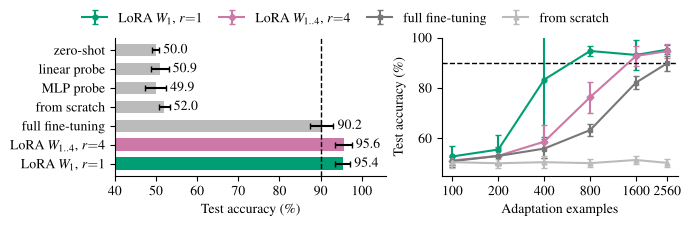

In [7]:
SHOW = ["Zero-shot", "Linear probe", "MLP probe", "Scratch (same architecture)", "Full fine-tuning",
        "LoRA, W1-W4, r=4", "LoRA, W1, r=1"]
LABEL = {"Zero-shot": "zero-shot", "Linear probe": "linear probe", "MLP probe": "MLP probe",
         "Scratch (same architecture)": "from scratch", "Full fine-tuning": "full fine-tuning",
         "LoRA, W1-W4, r=4": r"LoRA $W_{1..4}$, $r{=}4$", "LoRA, W1, r=1": r"LoRA $W_1$, $r{=}1$"}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(FULL, 2.15), gridspec_kw={"width_ratios": [1.15, 1]})
stats = np.array([mean_ci(res[m]) for m in SHOW]) * 100
colors = ["#bbbbbb"] * 5 + [COLORS["adapt"], COLORS[40]]
ax.barh(range(len(SHOW)), stats[:, 0], xerr=stats[:, 1], color=colors, height=0.65, capsize=2)
for i, m in enumerate(SHOW):
    ax.text(stats[i, 0] + stats[i, 1] + 1, i, f"{stats[i, 0]:.1f}", va="center")
ax.axvline(90, color="k", ls="--", lw=1)
ax.set_yticks(range(len(SHOW))); ax.set_yticklabels([LABEL[m] for m in SHOW]); ax.invert_yaxis()
ax.set_xlim(40, 106); ax.set_xlabel(pct("Test accuracy (%)"))
ax.set_xticks([40, 50, 60, 70, 80, 90, 100])

for m, col, mk in (("LoRA, W1, r=1", COLORS[40], "o"), ("LoRA, W1-W4, r=4", COLORS["adapt"], "D"),
                   ("Full fine-tuning", "#777777", "s"), ("Scratch (same architecture)", "#bbbbbb", "^")):
    st = np.array([mean_ci(curve[m][s]) for s in SIZES]) * 100
    bx.errorbar(SIZES, st[:, 0], yerr=st[:, 1], color=col, marker=mk, ms=3.5, capsize=2, label=LABEL[m])
bx.axhline(90, color="k", ls="--", lw=1)
bx.set_xscale("log"); bx.set_xticks(SIZES); bx.set_xticklabels([str(s) for s in SIZES]); bx.minorticks_off()
bx.set_xlabel("Adaptation examples"); bx.set_ylabel(pct("Test accuracy (%)")); bx.set_ylim(45, 100)
fig.legend(*bx.get_legend_handles_labels(), ncol=4, loc="outside upper center", handlelength=1.8, columnspacing=1.2)
save(fig, "fig4_kryptonet")
plt.show()

**Reading Figure 4.** Left: frozen-representation methods and training from scratch stay at chance; full
fine-tuning of all 809,473 parameters works but overfits; LoRA on the first layer with rank 1 (552 trainable
parameters) reaches the Bayes level of ~96%, matching the analytic rank-1 edit.  Right: rank-1 LoRA needs only a
few hundred labelled examples, while full fine-tuning needs thousands and training from scratch never leaves chance.